## LINEAR REGRESSION

In [1]:
SEED = 42

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import MLUtils 

from sklearn.linear_model import Ridge, RidgeCV, LinearRegression
from sklearn.model_selection import KFold, StratifiedKFold

In [3]:
de_train_path = "/Users/jennyng/Desktop/Projects/kaggle/single-cell-perturbations/data/de_train.parquet"
de_train = pd.read_parquet(de_train_path)
de_train.head()

,cell_type,sm_name,sm_lincs_id,SMILES,control,A1BG,A1BG-AS1,A2M,A2M-AS1,A2MP1,...,ZUP1,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1
0,NK cells,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,0.104720,-0.077524,-1.625596,-0.144545,0.143555,...,-0.227781,-0.010752,-0.023881,0.674536,-0.453068,0.005164,-0.094959,0.034127,0.221377,0.368755
1,T cells CD4+,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,0.915953,-0.884380,0.371834,-0.081677,-0.498266,...,-0.494985,-0.303419,0.304955,-0.333905,-0.315516,-0.369626,-0.095079,0.704780,1.096702,-0.869887
2,T cells CD8+,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,-0.387721,-0.305378,0.567777,0.303895,-0.022653,...,-0.119422,-0.033608,-0.153123,0.183597,-0.555678,-1.494789,-0.213550,0.415768,0.078439,-0.259365
3,T regulatory cells,Clotrimazole,LSM-5341,Clc1ccccc1C(c1ccccc1)(c1ccccc1)n1ccnc1,False,0.232893,0.129029,0.336897,0.486946,0.767661,...,0.451679,0.704643,0.015468,-0.103868,0.865027,0.189114,0.224700,-0.048233,0.216139,-0.085024
4,NK cells,Mometasone Furoate,LSM-3349,C[C@@H]1C[C@H]2[C@@H]3CCC4=CC(=O)C=C[C@]4(C)[C...,False,4.290652,-0.063864,-0.017443,-0.541154,0.570982,...,0.758474,0.510762,0.607401,-0.123059,0.214366,0.487838,-0.819775,0.112365,-0.122193,0.676629


### Implement OLS

In [4]:
# implement OLS

class OrdinaryLeastSquares:

    def r_square(self, y_true, y_hat):
        y_true = np.asarray(y_true)
        y_hat = np.asarray(y_hat)

        ss_residuals = ((y_true-y_hat)**2).sum(axis=0)   # error between predictions and y_true
        y_bar = y_true.mean(axis=0)   
        ss_total = ((y_true-y_bar)**2).sum(axis=0)  # error between y_mean and y_true
        # print(ss_total)
        return 1 - (ss_residuals/ss_total)

    def fit(self, X, y):
        # self.beta = np.linalg.inv(X.T @ X) @ X.T @ y # normal equation 

        X_with_intercept = np.column_stack([np.ones(X.shape[0]), X])
        coefficients, *_ = np.linalg.lstsq(X_with_intercept, y, rcond=None)

        # XtX = X_with_intercept.T @ X_with_intercept
        # Xty = X_with_intercept.T @ y
        # coefficients = np.linalg.solve(XtX, Xty)    # allegedely more stable
        
        self.intercept = coefficients[0]
        self.beta = coefficients[1:]
    
    def predict(self, X):
        return X @ self.beta + self.intercept


In [62]:
# test OLS
rng = np.random.default_rng(0)
n, p = 100, 3
X = rng.normal(size=(n,p))
# X = np.column_stack([np.ones(n), X])
true_beta = np.array([-1.0, 0.5, 3.0])
y = X @ true_beta

model = OrdinaryLeastSquares()
model.fit(X, y)
y_hat = model.predict(X)
print(model.r_square(y, y_hat))

1.0


In [63]:
y_noisy = X @ true_beta + rng.normal(scale=0.1, size=n)

model = OrdinaryLeastSquares()
model.fit(X, y_noisy)
y_hat = model.predict(X)
print(model.r_square(y_noisy, y_hat))

0.9991646069467615


### One-Hot Encoding

In [1]:
from sklearn.preprocessing import OneHotEncoder

In [6]:
sm_cats = np.sort(de_train['sm_name'].unique()).reshape(-1, 1)
sm_cats

array([['5-(9-Isopropyl-8-methyl-2-morpholino-9H-purin-6-yl)pyrimidin-2-amine'],
       ['ABT-199 (GDC-0199)'],
       ['ABT737'],
       ['AMD-070 (hydrochloride)'],
       ['AT 7867'],
       ['AT13387'],
       ['AVL-292'],
       ['AZ628'],
       ['AZD-8330'],
       ['AZD3514'],
       ['AZD4547'],
       ['Alogliptin'],
       ['Alvocidib'],
       ['Amiodarone'],
       ['Atorvastatin'],
       ['Azacitidine'],
       ['BAY 61-3606'],
       ['BAY 87-2243'],
       ['BI-D1870'],
       ['BMS-265246'],
       ['BMS-387032'],
       ['BMS-536924'],
       ['BMS-777607'],
       ['BX 912'],
       ['Belinostat'],
       ['Bosutinib'],
       ['Buspirone'],
       ['CC-401'],
       ['CEP-18770 (Delanzomib)'],
       ['CEP-37440'],
       ['CGM-097'],
       ['CGP 60474'],
       ['CHIR-99021'],
       ['Cabozantinib'],
       ['Canertinib'],
       ['Ceritinib'],
       ['Chlorpheniramine'],
       ['Clemastine'],
       ['Clomipramine'],
       ['Clotrimazole'],
       ['Colchici

In [7]:
ohe = OneHotEncoder(sparse_output=False, dtype=np.int8)
M = ohe.fit_transform(sm_cats)
M

array([[1, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 1, 0],
       [0, 0, 0, ..., 0, 0, 1]], shape=(146, 146), dtype=int8)

In [8]:
onehot_sm = pd.DataFrame(
    M,
    index=pd.Index(sm_cats.ravel(), name='sm_name'),
    columns=ohe.get_feature_names_out(['sm_name'])
)
onehot_sm

,sm_name_5-(9-Isopropyl-8-methyl-2-morpholino-9H-purin-6-yl)pyrimidin-2-amine,sm_name_ABT-199 (GDC-0199),sm_name_ABT737,sm_name_AMD-070 (hydrochloride),sm_name_AT 7867,sm_name_AT13387,sm_name_AVL-292,sm_name_AZ628,sm_name_AZD-8330,sm_name_AZD3514,sm_name_AZD4547,sm_name_Alogliptin,sm_name_Alvocidib,sm_name_Amiodarone,sm_name_Atorvastatin,sm_name_Azacitidine,sm_name_BAY 61-3606,sm_name_BAY 87-2243,sm_name_BI-D1870,sm_name_BMS-265246,sm_name_BMS-387032,sm_name_BMS-536924,sm_name_BMS-777607,sm_name_BX 912,sm_name_Belinostat,sm_name_Bosutinib,sm_name_Buspirone,sm_name_CC-401,sm_name_CEP-18770 (Delanzomib),sm_name_CEP-37440,sm_name_CGM-097,sm_name_CGP 60474,sm_name_CHIR-99021,sm_name_Cabozantinib,sm_name_Canertinib,sm_name_Ceritinib,sm_name_Chlorpheniramine,sm_name_Clemastine,sm_name_Clomipramine,sm_name_Clotrimazole,...,sm_name_Protriptyline,sm_name_Quizartinib,sm_name_R428,sm_name_RG7090,sm_name_RG7112,sm_name_RN-486,sm_name_RVX-208,sm_name_Raloxifene,sm_name_Resminostat,sm_name_Ricolinostat,sm_name_Riociguat,sm_name_Ruxolitinib,sm_name_SB525334,sm_name_SCH-58261,sm_name_SLx-2119,sm_name_STK219801,sm_name_Saracatinib,sm_name_Scriptaid,sm_name_Selumetinib,sm_name_Sgc-cbp30,sm_name_Sunitinib,sm_name_TGX 221,sm_name_TIE2 Kinase Inhibitor,sm_name_TL_HRAS26,sm_name_TPCA-1,sm_name_TR-14035,sm_name_Tacalcitol,sm_name_Tamatinib,sm_name_Tipifarnib,sm_name_Tivantinib,sm_name_Tivozanib,sm_name_Topotecan,sm_name_Tosedostat,sm_name_Trametinib,sm_name_UNII-BXU45ZH6LI,sm_name_Vandetanib,sm_name_Vanoxerine,sm_name_Vardenafil,sm_name_Vorinostat,sm_name_YK 4-279
sm_name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5-(9-Isopropyl-8-methyl-2-morpholino-9H-purin-6-yl)pyrimidin-2-amine,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
ABT-199 (GDC-0199),0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
ABT737,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
AMD-070 (hydrochloride),0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
AT 7867,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Vandetanib,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
Vanoxerine,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
Vardenafil,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


In [9]:
onehot_sm.to_csv("processed_data/onehot_sm_name.csv")

In [10]:
cell_cats = np.sort(de_train['cell_type'].unique()).reshape(-1, 1)
M = ohe.fit_transform(cell_cats)
onehot_cell_type = pd.DataFrame(
    M,
    index=pd.Index(cell_cats.ravel(), name='cell_type'),
    columns=ohe.get_feature_names_out(['cell_type'])
)
onehot_cell_type

,cell_type_B cells,cell_type_Myeloid cells,cell_type_NK cells,cell_type_T cells CD4+,cell_type_T cells CD8+,cell_type_T regulatory cells
cell_type,,,,,,
B cells,1,0,0,0,0,0
Myeloid cells,0,1,0,0,0,0
NK cells,0,0,1,0,0,0
T cells CD4+,0,0,0,1,0,0
T cells CD8+,0,0,0,0,1,0
T regulatory cells,0,0,0,0,0,1


In [11]:
onehot_cell_type.to_csv("processed_data/onehot_cell_type.csv")

### TRAIN

In [5]:
onehot_sm = pd.read_csv("processed_data/onehot_sm_name.csv", index_col="sm_name")
ohe_sm_map = dict(zip(onehot_sm.index, onehot_sm.to_numpy()))
onehot_cell = pd.read_csv("processed_data/onehot_cell_type.csv", index_col="cell_type")
ohe_cell_map = dict(zip(onehot_cell.index, onehot_cell.to_numpy()))

In [6]:
strat_labels = de_train["sm_name"]
skf = StratifiedKFold(shuffle=True, random_state=SEED)

In [7]:
X_tr, y_tr = MLUtils.featurize_cell_sm(de_train, ohe_cell_map, ohe_sm_map)
skf_folds = list(skf.split(X_tr, strat_labels))
ols_model = OrdinaryLeastSquares()
sgkf = StratifiedKFold()
MLUtils.train(X_tr, y_tr, ols_model, skf_folds, pca_y=None, scaler=None)

/Users/jennyng/miniforge3/envs/bioml/lib/python3.11/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


{'folds': [1.4604459799288891,
  1.2739146124365683,
  1.4200793284702533,
  1.2826829950165248,
  1.3384909829560439],
 'mean': 1.3551227797616558}

In [9]:
scikit_ols = LinearRegression()
MLUtils.train(X_tr, y_tr, scikit_ols, skf_folds, pca_y=None, scaler=None)

{'folds': [1.46044597992889,
  1.2739146124365672,
  1.4200793284702538,
  1.2826829950165248,
  1.3384909829560423],
 'mean': 1.3551227797616554}

### Implement Ridge Regression

Adding a penalty term to the loss function
E = Σ(y - y^i)^2 + λΣw^2

In [11]:
class RidgeClass():

    def __init__(self, alpha=0.1):
        self.alpha = alpha

    def fit(self, X, y):
        # beta = (XTX + λI)^-1XTy
        X_with_intercept = np.column_stack([np.ones(X.shape[0]), X])
        # print(X_with_intercept)
        XtX = X_with_intercept.T @ X_with_intercept
        XTy = X_with_intercept.T @ y

        identity_matrix = np.identity(X_with_intercept.shape[1])
        penalty = self.alpha * identity_matrix
        penalty[0][0] = 0   # convention to not penalize intercept

        coefficients = np.linalg.solve(XtX + penalty, XTy)

        self.intercept = coefficients[0]
        self.beta = coefficients[1:]

    def predict(self, X):
        return X @ self.beta + self.intercept

In [19]:
ridge_model = RidgeClass(alpha=0.1)
MLUtils.train(X_tr, y_tr, ridge_model, skf_folds, pca_y=None, scaler=None)

{'folds': [1.446809292140629,
  1.2676357834188088,
  1.408817006579177,
  1.2718534834918713,
  1.3276163205093325],
 'mean': 1.3445463772279638}

In [18]:
sciki_ridge = Ridge(alpha=0.1)
MLUtils.train(X_tr, y_tr, sciki_ridge, skf_folds, pca_y=None, scaler=None)

{'folds': [1.4468092921406266,
  1.267635783418809,
  1.4088170065791759,
  1.2718534834918722,
  1.3276163205093285],
 'mean': 1.3445463772279624}

**Finding best alpha**

In [22]:
alpha_range = np.logspace(-3, 3, 100)

In [33]:
alpha_mrrmse = {}
for a in alpha_range:
    sciki_ridge = Ridge(alpha=a)
    results = MLUtils.train(X_tr, y_tr, sciki_ridge, skf_folds, pca_y=None, scaler=None)
    avg_mrrmse = results['mean']
    alpha_mrrmse.update({a:avg_mrrmse})

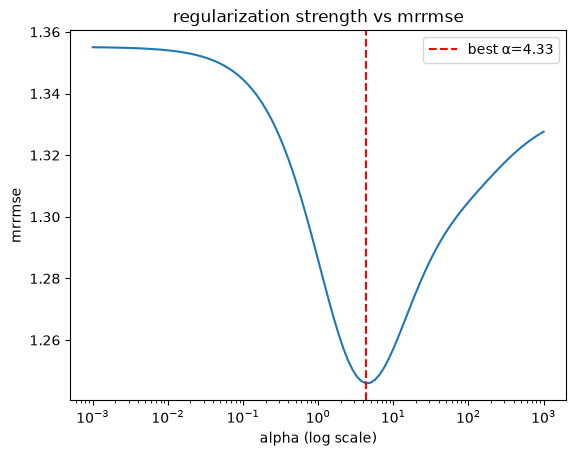

In [34]:
alphas = list(alpha_mrrmse.keys())
errors = list(alpha_mrrmse.values())

plt.plot(alphas, errors)
plt.xscale("log")
plt.title("regularization strength vs mrrmse")
plt.xlabel("alpha (log scale)")
plt.ylabel("mrrmse")

best_alpha = min(alpha_mrrmse, key=alpha_mrrmse.get)
plt.axvline(best_alpha, color="red", ls="--", label=f"best α={best_alpha:.3g}")
plt.legend()

In [35]:
alpha_mrrmse = {}
for a in alpha_range:
    ridge_model = RidgeClass(alpha=a)
    results = MLUtils.train(X_tr, y_tr, ridge_model, skf_folds, pca_y=None, scaler=None)
    avg_mrrmse = results['mean']
    alpha_mrrmse.update({a:avg_mrrmse})

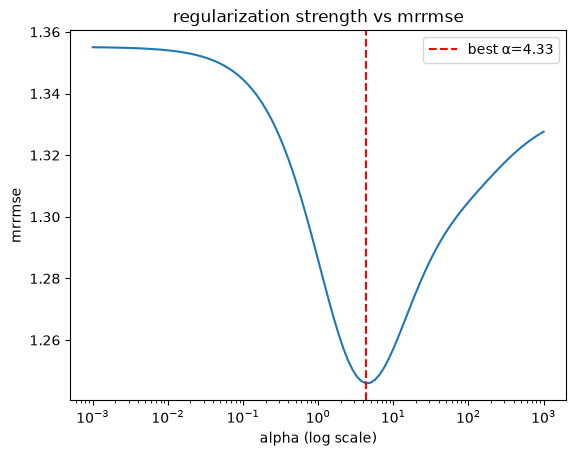

In [36]:
alphas = list(alpha_mrrmse.keys())
errors = list(alpha_mrrmse.values())

plt.plot(alphas, errors)
plt.xscale("log")
plt.title("regularization strength vs mrrmse")
plt.xlabel("alpha (log scale)")
plt.ylabel("mrrmse")

best_alpha = min(alpha_mrrmse, key=alpha_mrrmse.get)
plt.axvline(best_alpha, color="red", ls="--", label=f"best α={best_alpha:.3g}")
plt.legend()

**PICKLE SPLITZ**

In [40]:
import pickle

In [41]:
path = "/Users/jennyng/Desktop/Projects/kaggle/single-cell-perturbations/processed_data/train_test_splits.pkl"
with open(path, "rb") as f:
    folds = pickle.load(f)

In [42]:
X_tr, y_tr = MLUtils.featurize_cell_sm(de_train, ohe_cell_map, ohe_sm_map)
ridge_cv = RidgeCV()
MLUtils.train(X_tr, y_tr, ridge_cv, folds, pca_y=None, scaler=None)

{'folds': [1.2198798951114336,
  1.1566684821245727,
  1.5946177403296047,
  1.3199087649690802,
  1.5874605045732133,
  1.203762765253916,
  1.0084411753031786,
  1.1312176102300098,
  1.2383773958256767,
  1.5318245361075127],
 'mean': 1.2992158869828196}

### Ensemble median + Ridge

In [48]:
weights = np.linspace(0, 1, 21)
fold_scores = {w: [] for w in weights}

for i, (train_idx, test_idx) in enumerate(folds):
    ridge_cv = RidgeCV(alphas=alpha_range)
    X_train = X_tr.iloc[train_idx]
    y_train = y_tr.iloc[train_idx]
    X_test = X_tr.iloc[test_idx]
    y_test = y_tr.iloc[test_idx]
    
    ridge_cv.fit(X_train, y_train)
    ridge_pred = ridge_cv.predict(X_test)

    median_vec = y_train.median().values

    for w in weights: 
        blend = w * ridge_pred + (1-w) * median_vec
        err = MLUtils.mrrmse(y_test, blend)
        fold_scores[w].append(err)

mean_scores = {w: np.mean(s) for w, s in fold_scores.items()}
best_w = min(mean_scores, key=mean_scores.get)
print(f"best w={best_w:.2f}, MRRMSE={mean_scores[best_w]:.4f}")

best w=0.50, MRRMSE=1.2005


### Leak-free weighted ensemble (nested CV)

The ensemble strategy above chooses `best_w` by minimizing MRRMSE on the test folds. Below, an inner CV selects the weight using training data only, and the outer pickled folds evaluate it. This prevents data leakage across train and test folds.

In [50]:
# inner CV selects the blend weight (train rows only); outer CV (pickled folds) evaluates.
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_predict

weights = np.linspace(0, 1, 21)

def select_weight(X_tr, y_tr, seed=SEED):
    """Pick the ridge/median blend weight using ONLY training rows (out-of-fold)."""
    inner_cv   = KFold(n_splits=5, shuffle=True, random_state=seed)
    ridge_oof  = cross_val_predict(RidgeCV(), X_tr, y_tr, cv=inner_cv)
    median_oof = cross_val_predict(DummyRegressor(strategy="median"), X_tr, y_tr, cv=inner_cv)
    scores = {w: MLUtils.mrrmse(y_tr, w * ridge_oof + (1 - w) * median_oof) for w in weights}
    return min(scores, key=scores.get)

In [52]:
# Outer loop = pickled folds. Weight chosen without ever seeing the outer test fold.
outer_scores, chosen_ws = [], []

for i, (train_idx, test_idx) in enumerate(folds):
    X_train = X_tr.iloc[train_idx]
    y_train = y_tr.iloc[train_idx]
    X_test = X_tr.iloc[test_idx]
    y_test = y_tr.iloc[test_idx]

    w = select_weight(X_train, y_train)                       # selected on train only

    ridge  = RidgeCV().fit(X_train, y_train)
    median = DummyRegressor(strategy="median").fit(X_train, y_train)
    blend  = w * ridge.predict(X_test) + (1 - w) * median.predict(X_test)

    err = MLUtils.mrrmse(y_test, blend)
    outer_scores.append(err); chosen_ws.append(w)
    print(f"fold {i}: chosen w={w:.2f}, MRRMSE={err:.4f}")

print(f"\nNested-CV MRRMSE = {np.mean(outer_scores):.4f} +/- {np.std(outer_scores):.4f}")
print(f"weights chosen per fold: {chosen_ws}")

fold 0: chosen w=0.40, MRRMSE=1.1723
fold 1: chosen w=0.40, MRRMSE=1.0596
fold 2: chosen w=0.40, MRRMSE=1.4715
fold 3: chosen w=0.40, MRRMSE=1.1660
fold 4: chosen w=0.45, MRRMSE=1.6281
fold 5: chosen w=0.45, MRRMSE=1.0653
fold 6: chosen w=0.40, MRRMSE=0.8843
fold 7: chosen w=0.45, MRRMSE=0.9666
fold 8: chosen w=0.45, MRRMSE=1.1104
fold 9: chosen w=0.40, MRRMSE=1.4944

Nested-CV MRRMSE = 1.2019 +/- 0.2336
weights chosen per fold: [np.float64(0.4), np.float64(0.4), np.float64(0.4), np.float64(0.4), np.float64(0.45), np.float64(0.45), np.float64(0.4), np.float64(0.45), np.float64(0.45), np.float64(0.4)]


In [53]:
# To DEPLOY final model, pick ONE weight using all data
deploy_w = select_weight(X_tr, y_tr)
print(f"deployment weight = {deploy_w:.2f}")

deployment weight = 0.40


### Fitting model on residual

Since median baseline seem to have good performance, we can fit a model on the residuals of the baseline model. 

In [47]:
mrrmse_list = []
alpha_list = []

for i, (train_idx, test_idx) in enumerate(folds):
    X_train = X_tr.iloc[train_idx]
    y_train = y_tr.iloc[train_idx]
    X_test = X_tr.iloc[test_idx]
    y_test = y_tr.iloc[test_idx]

    y_hat_baseline = y_train.median()

    y_train_res = y_train - y_hat_baseline

    # fit model trained on residual
    res_model = RidgeCV()
    res_model.fit(X_train, y_train_res)

    y_hat = res_model.predict(X_test) + y_hat_baseline.to_numpy()

    err = MLUtils.mrrmse(y_test, y_hat)
    print(f"fold {i}, mrrmse = {err}")
    mrrmse_list.append(err)
    alpha_list.append(res_model.alpha_)

avg_mrrmse = sum(mrrmse_list)/len(mrrmse_list)
print(f"avg MRRMSE = {avg_mrrmse}")

fold 0, mrrmse = 1.2198798951114336
fold 1, mrrmse = 1.1566684821245727
fold 2, mrrmse = 1.5946177403296047
fold 3, mrrmse = 1.3199087649690802
fold 4, mrrmse = 1.5874605045732133
fold 5, mrrmse = 1.203762765253916
fold 6, mrrmse = 1.0084411753031786
fold 7, mrrmse = 1.1312176102300098
fold 8, mrrmse = 1.2383773958256767
fold 9, mrrmse = 1.531824536107513
avg MRRMSE = 1.2992158869828196
